# 03 — Analisis Univariat
**Proyek EDA: Analisis Kebiasaan Penggunaan Ponsel Sebelum Tidur & Sleep Debt**
Exploratory Data Analysis (KMTI21133) · Milestone 3

**Pertanyaan payung:** Bagaimana kebiasaan memakai ponsel sebelum tidur berhubungan dengan kualitas tidur, sleep debt, dan kelelahan keesokan harinya?

**Pertanyaan turunan**
1. Bagaimana tren *sleep latency*, total tidur, dan kelelahan ketika durasi pakai ponsel sebelum tidur bertambah?
2. Apakah jenis aplikasi, kecerahan layar, dan filter cahaya biru membedakan *sleep latency*?
3. Variabel apa yang paling berhubungan dengan kelelahan, dan kelompok mana yang paling berisiko *sleep debt*?

## 0. Persiapan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

# Path RELATIF (aturan panduan). Jalankan dari folder notebooks/ (atau dari akar repositori).
NAMA = 'bedtime_screentime_sleep_debt_bersih.csv'
KANDIDAT = [f'../data/processed/{NAMA}', f'data/processed/{NAMA}', NAMA]
PATH = next((p for p in KANDIDAT if os.path.exists(p)), None)
if PATH is None:
    try:                                   # fallback khusus Colab: unggah manual
        from google.colab import files
        files.upload(); PATH = NAMA
    except ImportError:
        raise FileNotFoundError(f'Letakkan {NAMA} di data/processed/ lalu jalankan ulang.')

FIG = '../reports/figures' if PATH.startswith('../') else 'reports/figures'
os.makedirs(FIG, exist_ok=True)
def simpan(nama):
    plt.savefig(f'{FIG}/{nama}.png', dpi=150, bbox_inches='tight')

df = pd.read_csv(PATH)
print('Data      :', PATH)
print('Dimensi   :', df.shape)
print('Total NaN :', int(df.isna().sum().sum()))

Data      : ../data/processed/bedtime_screentime_sleep_debt_bersih.csv
Dimensi   : (8500, 18)
Total NaN : 0


In [2]:
NUM = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct',
       'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
URUT_DEBT = ['Severe Sleep Debt', 'Moderate Debt', 'Mild Deficit', 'Optimal Recovery']
display(df.dtypes.to_frame('tipe').T)

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
tipe,str,int64,str,str,str,float64,str,float64,int64,float64,int64,float64,float64,float64,float64,int64,float64,str


## 1. Ringkasan statistik numerik

In [3]:
def ringkas(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        'n': s.notna().sum(), 'mean': s.mean(), 'median': s.median(), 'std': s.std(),
        'min': s.min(), 'max': s.max(), 'skew': s.skew(), 'kurtosis': s.kurt(),
        'outlier_bawah': int((s < lo).sum()), 'outlier_atas': int((s > hi).sum()),
        '%_di_min': 100 * (s == s.min()).mean(), '%_di_max': 100 * (s == s.max()).mean(),
    })

df[NUM].apply(ringkas).T.round(2)

,n,mean,median,std,min,max,skew,kurtosis,outlier_bawah,outlier_atas,%_di_min,%_di_max
age,8500.0,34.35,32.00,11.58,18.0,65.0,0.69,-0.34,0.0,0.0,2.69,0.47
bedtime_phone_minutes,8500.0,59.25,51.00,36.93,1.0,180.0,1.03,0.84,0.0,237.0,0.01,1.02
screen_brightness_pct,8500.0,55.16,55.00,19.63,10.0,100.0,-0.01,-0.34,0.0,0.0,1.40,1.46
caffeine_post_5pm_mg,8500.0,32.62,0.00,51.68,0.0,250.0,1.81,2.98,0.0,505.0,59.04,0.55
physical_activity_min,8500.0,35.70,35.00,20.82,0.0,112.0,0.26,-0.32,0.0,40.0,5.51,0.01
sleep_latency_min,8500.0,40.57,37.60,17.15,6.0,123.3,1.00,1.23,0.0,265.0,0.05,0.01
total_sleep_hours,8500.0,6.27,6.33,1.45,3.2,9.8,-0.16,-0.56,0.0,0.0,2.85,0.20
deep_sleep_pct,8500.0,21.73,21.90,3.03,8.1,28.0,-0.27,0.04,57.0,0.0,0.01,1.81
rem_sleep_pct,8500.0,19.10,19.10,2.54,9.6,27.0,-0.11,0.09,44.0,32.0,0.01,0.09
morning_alarm_snoozes,8500.0,2.77,3.00,1.70,0.0,7.0,0.34,-0.42,0.0,0.0,8.88,2.09


## 2. Distribusi variabel numerik

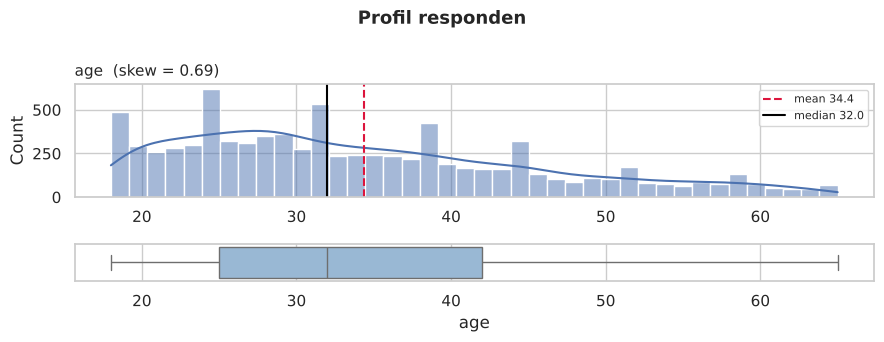

In [4]:
def profil(kolom, judul, nama_file):
    fig, axes = plt.subplots(len(kolom) * 2, 1, figsize=(9, 3.4 * len(kolom)),
                             gridspec_kw={'height_ratios': [3, 1] * len(kolom)})
    axes = np.atleast_1d(axes)
    for i, k in enumerate(kolom):
        s = df[k].dropna()
        ax_h, ax_b = axes[2 * i], axes[2 * i + 1]
        diskret = s.nunique() <= 10
        bins = np.arange(s.min() - .5, s.max() + 1.5, 1) if diskret else 40
        sns.histplot(s, bins=bins, kde=not diskret, ax=ax_h, color='#4C72B0')
        ax_h.axvline(s.mean(), color='crimson', ls='--', label=f'mean {s.mean():.1f}')
        ax_h.axvline(s.median(), color='black', label=f'median {s.median():.1f}')
        ax_h.set_title(f'{k}  (skew = {s.skew():.2f})', loc='left', fontsize=11)
        ax_h.set_xlabel(''); ax_h.legend(fontsize=8)
        sns.boxplot(x=s, ax=ax_b, color='#8FB8DE', fliersize=2)
        ax_b.set_xlabel(k); ax_b.set_yticks([])
        ax_h.sharex(ax_b)
    fig.suptitle(judul, y=1.0, fontsize=13, fontweight='bold')
    plt.tight_layout(); simpan(nama_file); plt.show()

profil(['age'], 'Profil responden', 'uni_01_profil')

**Usia.** Rentang 18–65 tahun (mean 34,4; median 32), miring ringan ke kanan (skew 0,69), tanpa outlier IQR.

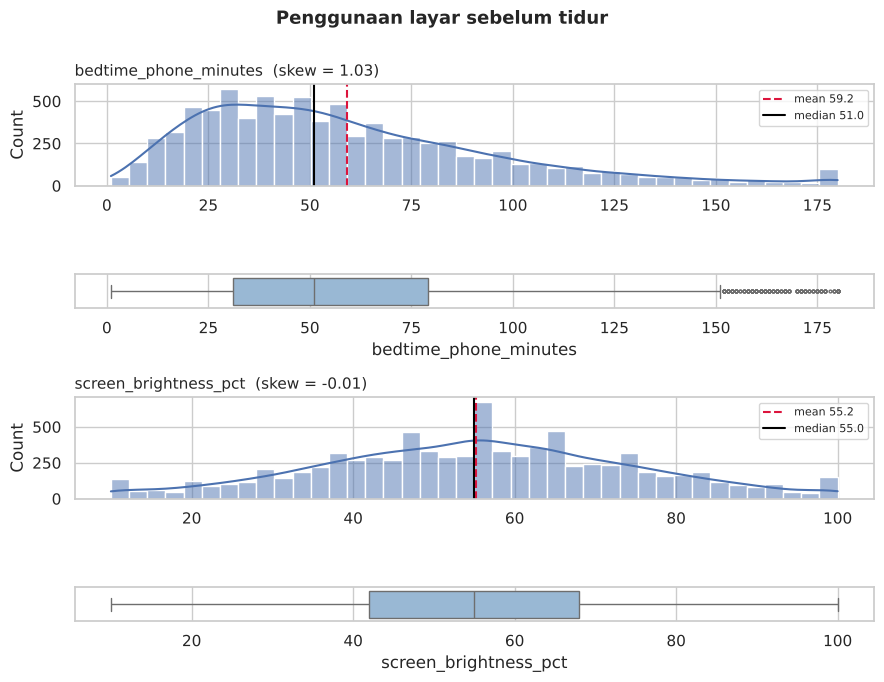

In [5]:
profil(['bedtime_phone_minutes', 'screen_brightness_pct'], 'Penggunaan layar sebelum tidur', 'uni_02_layar')

**Durasi ponsel sebelum tidur.** Miring kanan (skew 1,03; mean 59 > median 51 menit), dengan 237 outlier atas hingga 180 menit. Outlier dipertahankan karena merupakan ekor perilaku yang wajar, bukan kesalahan input. Sebanyak 87 responden tercatat tepat 180 menit, menandakan batas atas pengukuran.

**Kecerahan layar.** Hampir simetris (skew −0,01; mean ≈ median ≈ 55%), tanpa outlier.

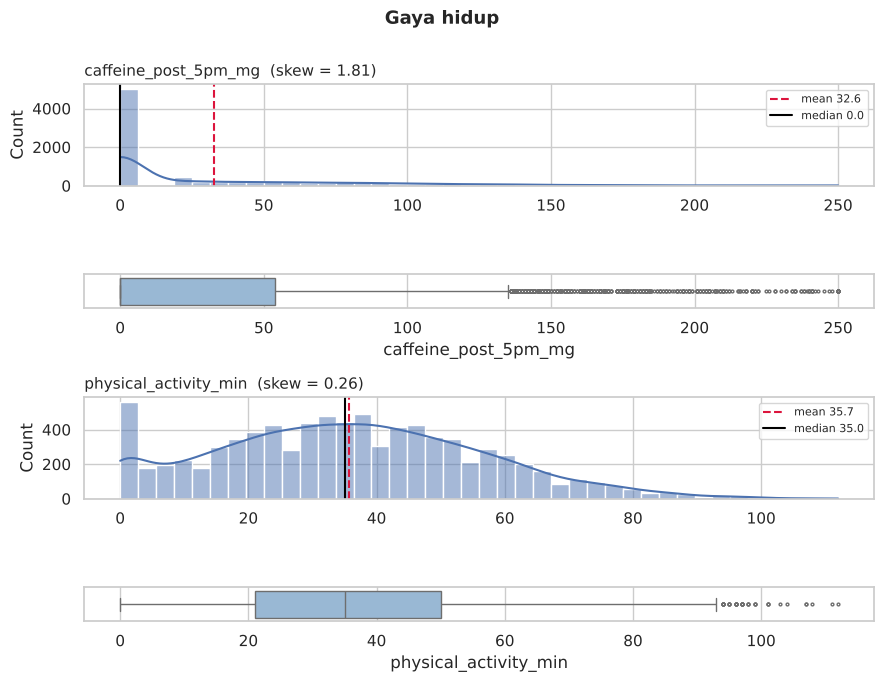

In [6]:
profil(['caffeine_post_5pm_mg', 'physical_activity_min'], 'Gaya hidup', 'uni_03_gaya_hidup')

**Kafein setelah pukul 17.00.** Zero-inflated: 59% responden (5.018 orang) tidak mengonsumsi kafein, sehingga median 0 dan mean 32,6 mg (skew 1,81; maksimum 250 mg). Outlier IQR (505) tidak dibuang karena batasnya dihitung dari sebaran yang didominasi nol.

**Aktivitas fisik.** Cukup simetris (skew 0,26; mean 35,7; median 35 menit). Ada 468 responden dengan 0 menit dan 40 outlier atas (maksimum 112 menit), keduanya masuk akal dan dipertahankan.

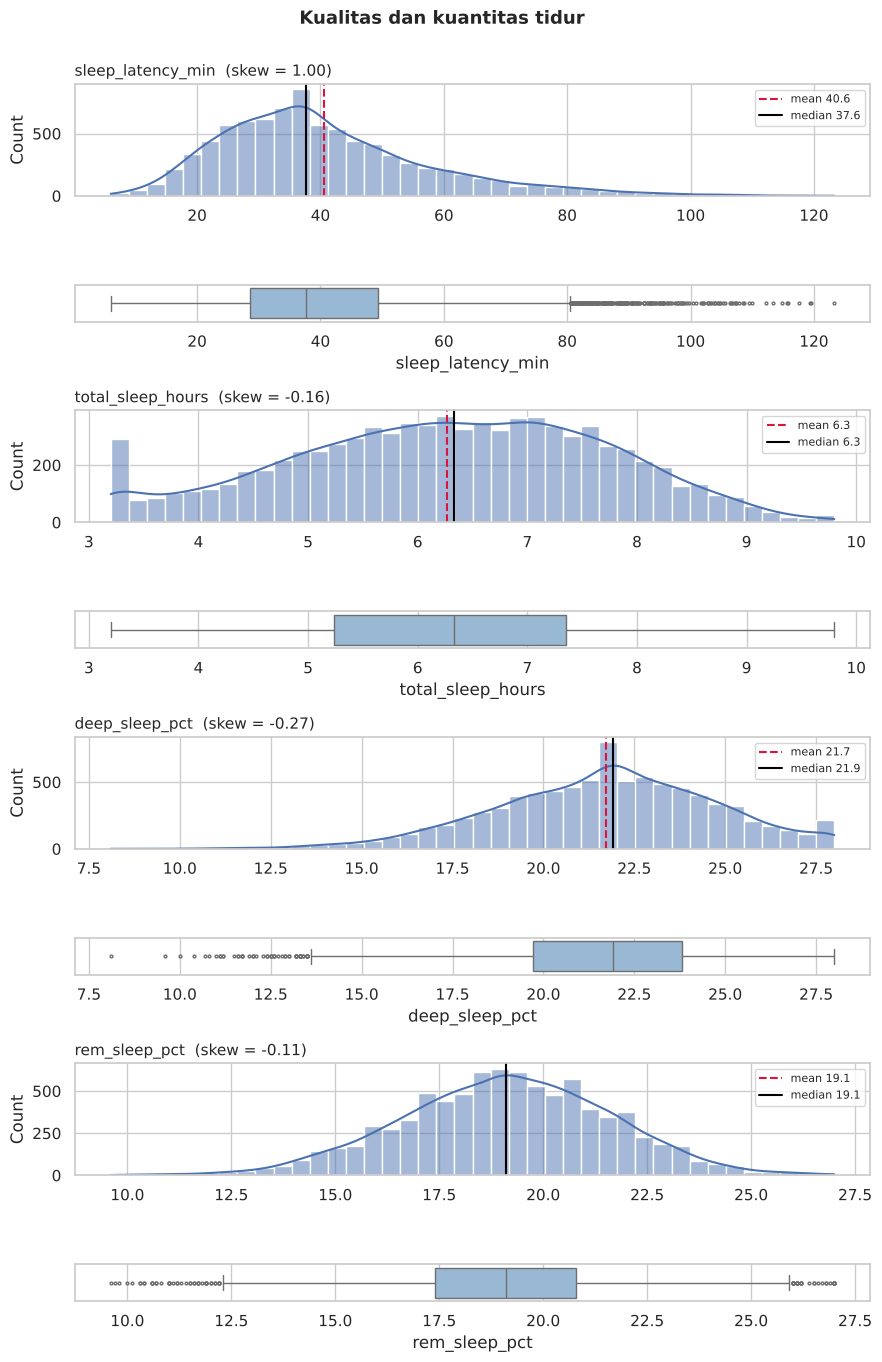

In [7]:
profil(['sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct'], 'Kualitas dan kuantitas tidur', 'uni_04_tidur')

**Sleep latency.** Miring kanan (skew 1,00; mean 40,6 > median 37,6 menit), 265 outlier atas dengan maksimum 123 menit. Nilai ekstrem tersebut masih mungkin secara fisiologis sehingga dipertahankan.

**Total tidur.** Hampir simetris (skew −0,16; mean 6,27; median 6,33 jam), rentang 3,2–9,8 jam, tanpa outlier IQR. Rata-ratanya berada di bawah anjuran 7–9 jam untuk dewasa. Ada penumpukan di batas bawah 3,2 jam (242 responden).

**Tidur dalam dan REM.** Mendekati normal (skew −0,27 dan −0,11; mean 21,7% dan 19,1%). Outlier IQR berjumlah kecil (< 1%) dan masih dalam rentang persentase yang masuk akal.

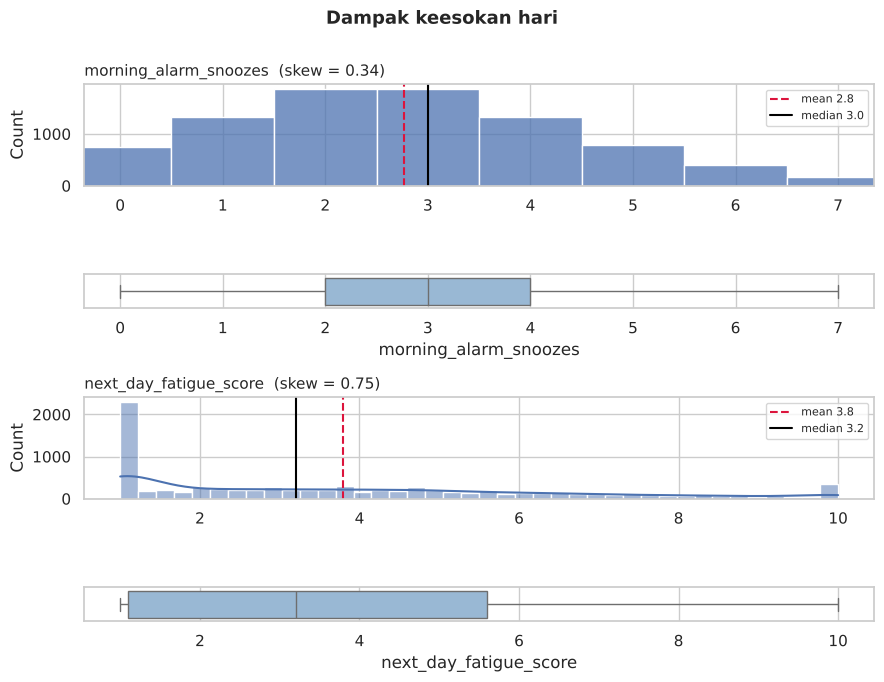

In [8]:
profil(['morning_alarm_snoozes', 'next_day_fatigue_score'], 'Dampak keesokan hari', 'uni_05_dampak')

**Snooze alarm.** Variabel cacah 0–7, puncak pada 2–3 kali (mean 2,8; median 3), skew 0,34, tanpa outlier.

**Skor kelelahan.** Skala 1–10, miring kanan (skew 0,75; mean 3,8 > median 3,2). Menumpuk di kedua ujung skala: 24,8% responden (2.110) bernilai tepat 1,0 dan 3,7% (314) bernilai tepat 10,0.

## 3. Variabel kategorikal

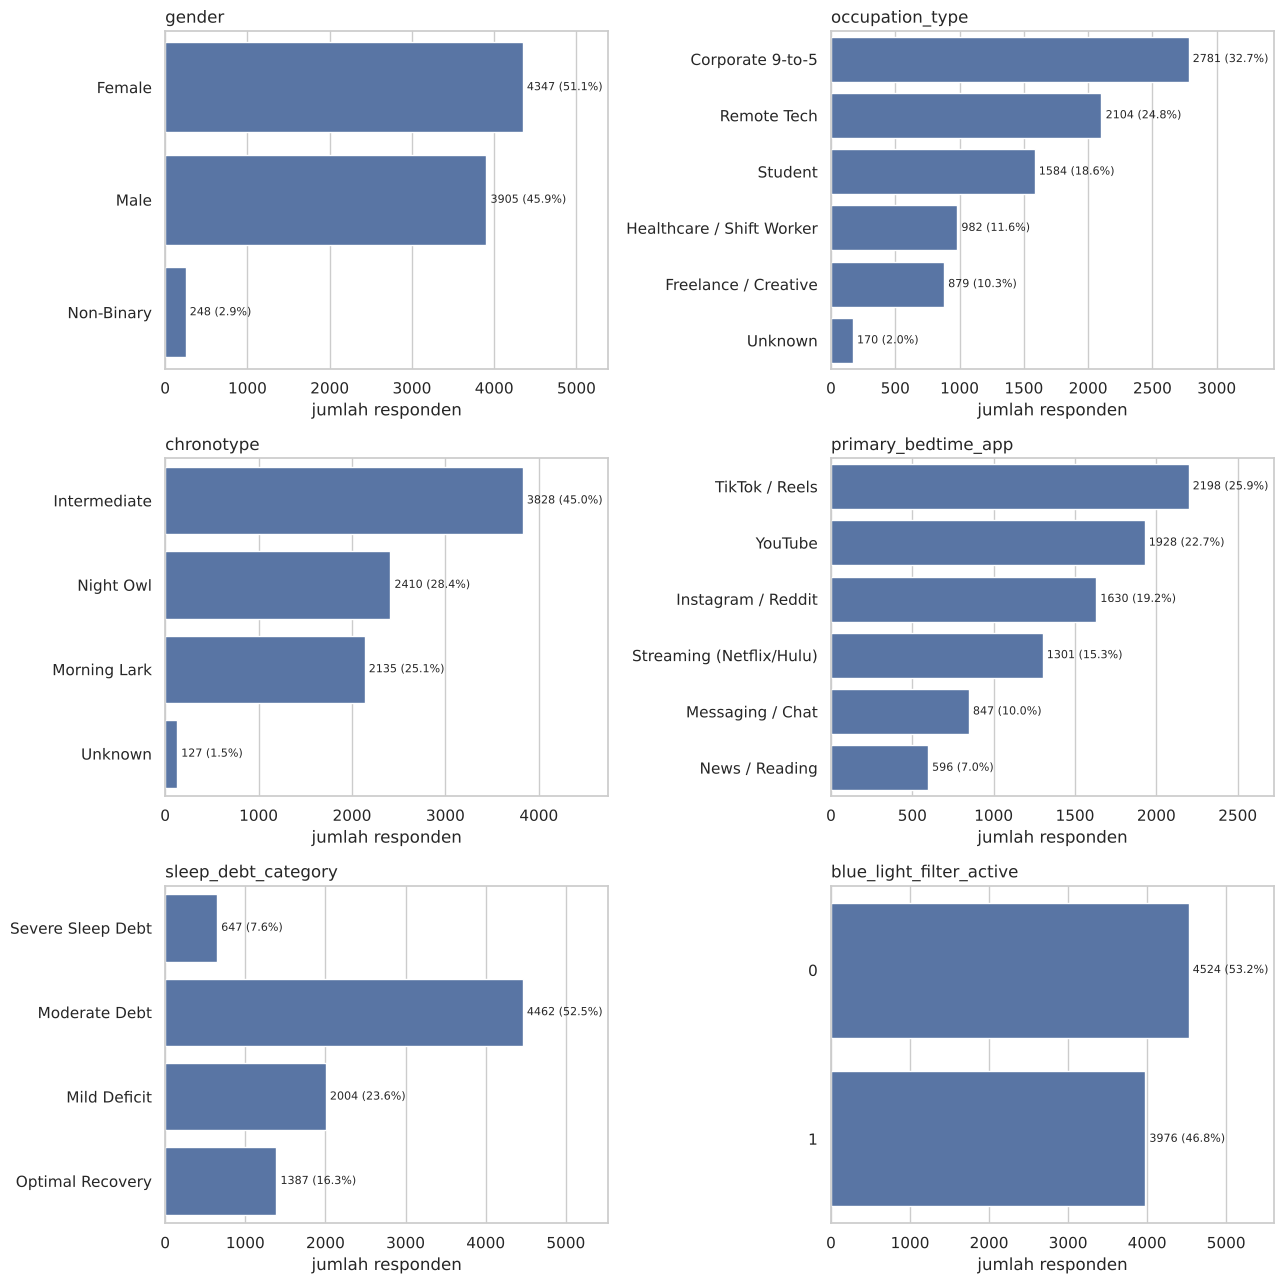

In [9]:
KAT = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'sleep_debt_category', 'blue_light_filter_active']
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, k in zip(axes.ravel(), KAT):
    urut = URUT_DEBT if k == 'sleep_debt_category' else df[k].value_counts().index
    sns.countplot(data=df, y=k, order=urut, ax=ax, color='#4C72B0')
    for p in ax.patches:
        ax.annotate(f'{p.get_width():.0f} ({100 * p.get_width() / len(df):.1f}%)',
                    (p.get_width(), p.get_y() + p.get_height() / 2),
                    ha='left', va='center', fontsize=8, xytext=(3, 0), textcoords='offset points')
    ax.set_title(k, loc='left'); ax.set_xlabel('jumlah responden'); ax.set_ylabel('')
    ax.set_xlim(0, ax.get_xlim()[1] * 1.18)
plt.tight_layout(); simpan('uni_06_kategorikal'); plt.show()

- **Gender:** 51,1% perempuan, 45,9% laki-laki, 2,9% non-biner (248 orang).
- **Pekerjaan:** didominasi *Corporate 9-to-5* (32,7%) dan *Remote Tech* (24,8%); *Healthcare / Shift Worker* 11,6%. Terdapat 170 baris `Unknown` (2,0%).
- **Kronotipe:** *Intermediate* 45,0%, *Night Owl* 28,4%, *Morning Lark* 25,1%; 127 baris `Unknown` (1,5%).
- **Aplikasi sebelum tidur:** TikTok/Reels (25,9%) dan YouTube (22,7%) terbanyak; *News / Reading* paling sedikit (7,0%).
- **Sleep debt:** 52,5% *Moderate Debt*, 23,6% *Mild Deficit*, 16,3% *Optimal Recovery*, dan 7,6% *Severe Sleep Debt*. Mayoritas responden tidak berada pada kondisi tidur optimal.
- **Filter cahaya biru:** 46,8% responden mengaktifkannya.

## 4. Ringkasan dan implikasi untuk analisis berikutnya

| Temuan | Implikasi |
|---|---|
| Durasi ponsel, *sleep latency*, dan kafein miring kanan (skew ≥ 1) | Korelasi memakai Spearman sebagai ukuran utama |
| Kafein zero-inflated (59% nol) | Pearson kurang tepat untuk variabel ini |
| Skor kelelahan menumpuk di 1,0 (24,8%) dan 10,0 (3,7%) | Hubungan cenderung tidak linear; gunakan Spearman |
| Durasi ponsel terpotong di 180 menit; total tidur menumpuk di 3,2 jam | Efek pada kedua ujung ekstrem kemungkinan terunderestimasi |
| Outlier IQR pada ponsel, kafein, *sleep latency* | Dipertahankan: ekor perilaku yang wajar |
| `Unknown` pada `occupation_type` dan `chronotype` | Dijadikan NaN pada analisis bivariat; n dilaporkan setelah `dropna()` |
| Non-biner 2,9% dan *Severe Sleep Debt* 7,6% | Kelompok kecil; kesimpulan per kelompok bersifat terbatas |